# APN 6

In [6]:
# markov_check.py    •   Python 3.11  •  NumPy ≥ 2.0
import json, math, sys
import numpy as np

FILE = "sboxes/data/apn_6.json"           # <-- put your JSON filename here
EPS  = 1e-12                   # tolerance for t_mix
KMAX = 32                      # evaluate up to 32 rounds

# ------------------------------------------------------------------ #
# 1) Load file (expecting a list[list[int]] of equal-length rows)
# ------------------------------------------------------------------ #
try:
    with open(FILE, "r", encoding="utf-8") as fh:
        tables = json.load(fh)
except Exception as e:
    sys.exit(f"Cannot read {FILE}: {e}")

if not tables:
    sys.exit("No S-Boxes found!")

N = len(tables[0])            # 32  (must be 2^n)
n = int(math.log2(N))
assert 2 ** n == N, "Table length must be a power of 2"

# ------------------------------------------------------------------ #
def is_bijective(t: list[int]) -> bool:
    return len(t) == N and len(set(t)) == N

def normalised_ddt(table: list[int]) -> np.ndarray:
    """Return (N-1)×(N-1) matrix with rows/cols 0 removed and ÷2ⁿ."""
    ddt = np.zeros((N, N), dtype=int)
    for x in range(N):
        for dx in range(N):
            dy = table[x] ^ table[x ^ dx]
            ddt[dx, dy] += 1
    return ddt[1:, 1:] / N     # normalise → probabilities

def markov_metrics(P: np.ndarray,
                   eps=EPS,
                   k_max=KMAX) -> tuple[int, float, float]:
    """Return (t_mix, max_prob, d_tv) or (k_max, …) if not mixed."""
    size = P.shape[0]                 # N-1
    pi   = np.full(size, 1/size)
    PK   = np.eye(size)
    for k in range(1, k_max + 1):
        PK = PK @ P
        d_tv = 0.5 * np.abs(PK - pi).sum(axis=1).max()
        max_p = PK.max()
        if d_tv <= eps:
            return k, max_p, d_tv
    return k_max, max_p, d_tv         # still not at eps

# ------------------------------------------------------------------ #
print(f"{'Idx':>3}  Bijective  t_mix  max P^k   d_TV")
print("-"*41)

for idx, tbl in enumerate(tables, 1):
    if not is_bijective(tbl):
        print(f"{idx:>3}     NO     –––     –––       –––   (skipped)")
        continue

    P = normalised_ddt(tbl)
    t_mix, mprob, d_tv = markov_metrics(P)
    print(f"{idx:>3}    YES   {t_mix:>5}  {mprob:>8.4f}  {d_tv:>8.2e}")


Idx  Bijective  t_mix  max P^k   d_TV
-----------------------------------------
  1     NO     –––     –––       –––   (skipped)
  2     NO     –––     –––       –––   (skipped)
  3     NO     –––     –––       –––   (skipped)
  4     NO     –––     –––       –––   (skipped)
  5     NO     –––     –––       –––   (skipped)
  6     NO     –––     –––       –––   (skipped)
  7     NO     –––     –––       –––   (skipped)
  8     NO     –––     –––       –––   (skipped)
  9     NO     –––     –––       –––   (skipped)
 10     NO     –––     –––       –––   (skipped)
 11     NO     –––     –––       –––   (skipped)
 12     NO     –––     –––       –––   (skipped)
 13     NO     –––     –––       –––   (skipped)
 14     NO     –––     –––       –––   (skipped)
 15     NO     –––     –––       –––   (skipped)
 16     NO     –––     –––       –––   (skipped)
 17     NO     –––     –––       –––   (skipped)
 18     NO     –––     –––       –––   (skipped)
 19     NO     –––     –––       –––  

In [7]:
from sboxes.loader import load as load_sbox
from evaluation.identity_sbox import IdentitySBox
from evaluation.markov_chains.all_test_markov_chains import (
    compare_tv_distance,
    compare_max_probability,
    compare_mixing_times
)
TABLEAU10 = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]
TABLEAU10 = ["#e41a1c","#377eb8","#4daf4a","#984ea3","#ff7f00","#ffff33","#a65628","#f781bf","#999999"]

import seaborn as sns

COLORS_FOR_OWNS = sns.color_palette("ch:s=.25,rot=-.25", n_colors=48) [::-1]
#sns.palplot(sns.color_palette("Reds", n_colors=10))[::-3]  # Colores para las S-Boxes propias
COLORS_FOR_CLASICS = sns.color_palette("Reds", n_colors=10)[::-3]


In [8]:
from evaluation.avalanche_criterion import avalanche_criterion
from evaluation.fixed_points import fixed_ponts
from evaluation.uniformity import get_ddt
from evaluation.linearity import evaluate
from sboxes.loader import load as load_sbox

to_proof = ["nuestro 6", "fides_6_APN"]#"nuestro 5.v1", "nuestro 5.v2", "nuestro 5.v3"]

specs1 = []

for sbox_link in to_proof:
    sbox = load_sbox(f"sboxes/data/{sbox_link}.json")
    ddt = get_ddt(sbox)
    max_ddt = np.max(ddt[1:])        # ignoramos dx = 0
    uniformity = max_ddt
    fixed = fixed_ponts(sbox, detail=True)[1]
    non_linearities = evaluate(sbox)
    specs1.append({
        'name': sbox.name,
        'table': sbox.table.tolist(),
        'n_in': sbox.input_size,
        'n_out': sbox.output_size,
        'color': COLORS_FOR_CLASICS[len(specs1) % len(COLORS_FOR_CLASICS)],
        'sbox': sbox
        
    })
    print(f"Procesando S-Box: {sbox.name} ({sbox.input_size}x{sbox.output_size})")

0 -> 46
1 -> 56
2 -> 16
3 -> 57
4 -> 0
5 -> 61
6 -> 4
7 -> 62
8 -> 19
9 -> 35
10 -> 33
11 -> 9
12 -> 32
13 -> 39
14 -> 53
15 -> 22
16 -> 31
17 -> 20
18 -> 18
19 -> 58
20 -> 51
21 -> 47
22 -> 11
23 -> 24
24 -> 10
25 -> 36
26 -> 43
27 -> 42
28 -> 54
29 -> 48
30 -> 3
31 -> 63
32 -> 41
33 -> 55
34 -> 26
35 -> 12
36 -> 50
37 -> 44
38 -> 23
39 -> 60
40 -> 45
41 -> 52
42 -> 38
43 -> 29
44 -> 37
45 -> 5
46 -> 14
47 -> 34
48 -> 13
49 -> 8
50 -> 1
51 -> 27
52 -> 21
53 -> 2
54 -> 28
55 -> 59
56 -> 17
57 -> 40
58 -> 7
59 -> 15
60 -> 30
61 -> 49
62 -> 6
63 -> 25
Procesando S-Box: Nuestra 6 (6x6)
0 -> 54
1 -> 0
2 -> 48
3 -> 13
4 -> 15
5 -> 18
6 -> 35
7 -> 53
8 -> 63
9 -> 25
10 -> 45
11 -> 52
12 -> 3
13 -> 20
14 -> 33
15 -> 41
16 -> 8
17 -> 10
18 -> 57
19 -> 37
20 -> 59
21 -> 36
22 -> 34
23 -> 2
24 -> 26
25 -> 50
26 -> 28
27 -> 24
28 -> 60
29 -> 19
30 -> 14
31 -> 42
32 -> 46
33 -> 61
34 -> 5
35 -> 49
36 -> 31
37 -> 11
38 -> 28
39 -> 4
40 -> 12
41 -> 30
42 -> 55
43 -> 22
44 -> 9
45 -> 6
46 -> 32
47 ->

In [9]:
import json
from sboxes import SBox

specs2 = []
# ---------- 1. Cargar el JSON ----------
with open("sboxes/data/apn_6.json"  , "r", encoding="utf-8") as f:
    data = json.load(f)

# ---------- 2. Procesar cada S-Box ----------
for idx, sb in enumerate(data, 1):
 
    print(sb)        
    table = list(map(lambda x: hex(x), sb))                   # lista de enteros
    n_in  = 6           # nº de bits de entrada
    n_out = 6  # nº de bits de salida
    name = f"apn #{idx}"
    biggest_possible_output = 1 << n_out
    final_table = np.empty(len(table), dtype=np.uint64)
    for idx, i in enumerate(table):#sb["table"]):
        output = int(i, 0)
        if output > biggest_possible_output or output < 0:
            raise ValueError("Table values must be greater than or equal to 0 and less than or equal to 2^%d" % n_out)
        final_table[idx] = output
        
    sbox = SBox(n_in, n_out, final_table, name)                      # <- ajusta a tu clase
    print("size:",len(sb))
    specs2.append({
        "name": name,              # pon aquí el nombre que prefieras
        "table": sbox.table.tolist(),
        "n_in": n_in,
        "n_out": n_out,
        "color": COLORS_FOR_OWNS[len(specs2) % len(COLORS_FOR_OWNS)],
        "sbox":  sbox
    })

# ---------- 3. (Opcional) comprobar ----------
print(f"{len(specs2)} S-Boxes cargadas desde data.json")
for s in specs2:
    print(s["name"], "–", s["n_in"], "→", s["n_out"])

[23, 32, 6, 9, 22, 55, 30, 12, 4, 28, 11, 31, 49, 5, 61, 46, 42, 14, 19, 60, 24, 28, 50, 26, 2, 34, 36, 59, 37, 57, 10, 8, 41, 33, 20, 3, 52, 45, 25, 63, 53, 35, 18, 15, 13, 48, 0, 54, 44, 38, 43, 7, 56, 51, 47, 40, 1, 62, 29, 16, 17, 21, 39, 27]
size: 64
[23, 32, 6, 9, 22, 55, 30, 12, 4, 28, 11, 31, 49, 5, 61, 46, 41, 33, 20, 3, 52, 45, 25, 63, 53, 35, 18, 15, 13, 48, 0, 54, 44, 38, 43, 7, 56, 51, 47, 40, 1, 62, 29, 16, 17, 21, 39, 27, 42, 14, 19, 60, 24, 28, 50, 26, 2, 34, 36, 59, 37, 57, 10, 8]
size: 64
[46, 61, 5, 49, 31, 11, 28, 4, 12, 30, 55, 22, 9, 6, 32, 23, 27, 39, 21, 17, 16, 29, 62, 1, 40, 47, 51, 56, 7, 43, 38, 44, 54, 0, 48, 13, 15, 18, 35, 53, 63, 25, 45, 52, 3, 20, 33, 41, 8, 10, 57, 37, 59, 36, 34, 2, 26, 50, 28, 24, 60, 19, 14, 42]
size: 64
[8, 10, 57, 37, 59, 36, 34, 2, 26, 50, 28, 24, 60, 19, 14, 42, 46, 61, 5, 49, 31, 11, 28, 4, 12, 30, 55, 22, 9, 6, 32, 23, 54, 0, 48, 13, 15, 18, 35, 53, 63, 25, 45, 52, 3, 20, 33, 41, 27, 39, 21, 17, 16, 29, 62, 1, 40, 47, 51, 56, 

In [10]:
specs = specs1 + specs2

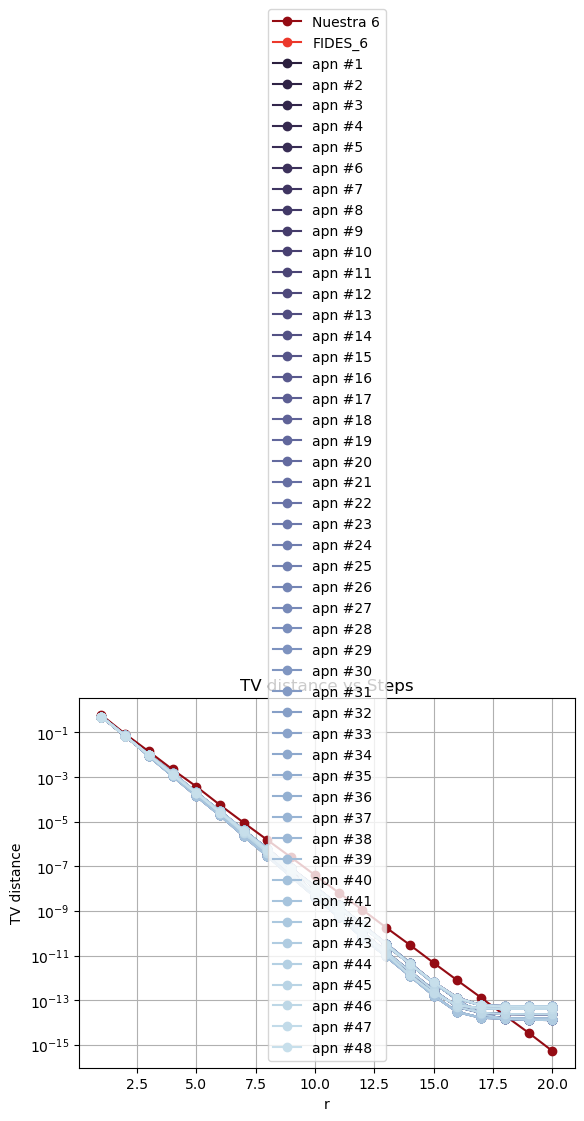

In [11]:
 # Comparaciones
ans = compare_tv_distance(specs, detail=False, graphic=True, log_scale=1)

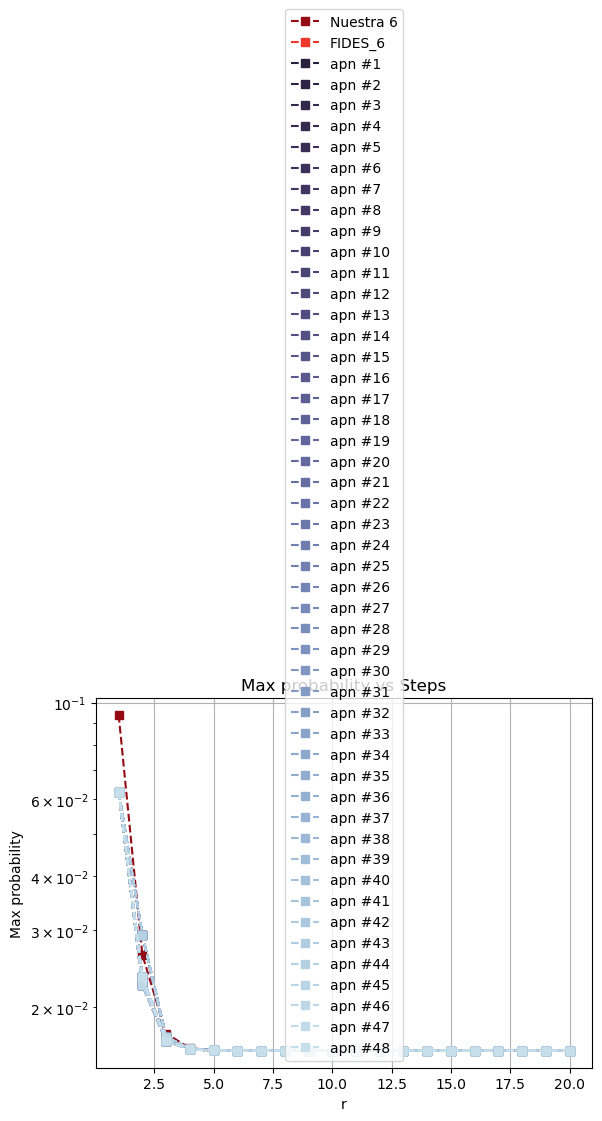

In [12]:
ans = compare_max_probability(specs, detail=False, graphic=True, log_scale=True)


|      ε |   Nuestra 6 iter |   FIDES_6 iter |   apn #1 iter |   apn #2 iter |   apn #3 iter |   apn #4 iter |   apn #5 iter |   apn #6 iter |   apn #7 iter |   apn #8 iter |   apn #9 iter |   apn #10 iter |   apn #11 iter |   apn #12 iter |   apn #13 iter |   apn #14 iter |   apn #15 iter |   apn #16 iter |   apn #17 iter |   apn #18 iter |   apn #19 iter |   apn #20 iter |   apn #21 iter |   apn #22 iter |   apn #23 iter |   apn #24 iter |   apn #25 iter |   apn #26 iter |   apn #27 iter |   apn #28 iter |   apn #29 iter |   apn #30 iter |   apn #31 iter |   apn #32 iter |   apn #33 iter |   apn #34 iter |   apn #35 iter |   apn #36 iter |   apn #37 iter |   apn #38 iter |   apn #39 iter |   apn #40 iter |   apn #41 iter |   apn #42 iter |   apn #43 iter |   apn #44 iter |   apn #45 iter |   apn #46 iter |   apn #47 iter |   apn #48 iter |   Nuestra 6 spec |   FIDES_6 spec |   apn #1 spec |   apn #2 spec |   apn #3 spec |   apn #4 spec |   apn #5 spec |   apn #6 spec |   apn #7 spec 

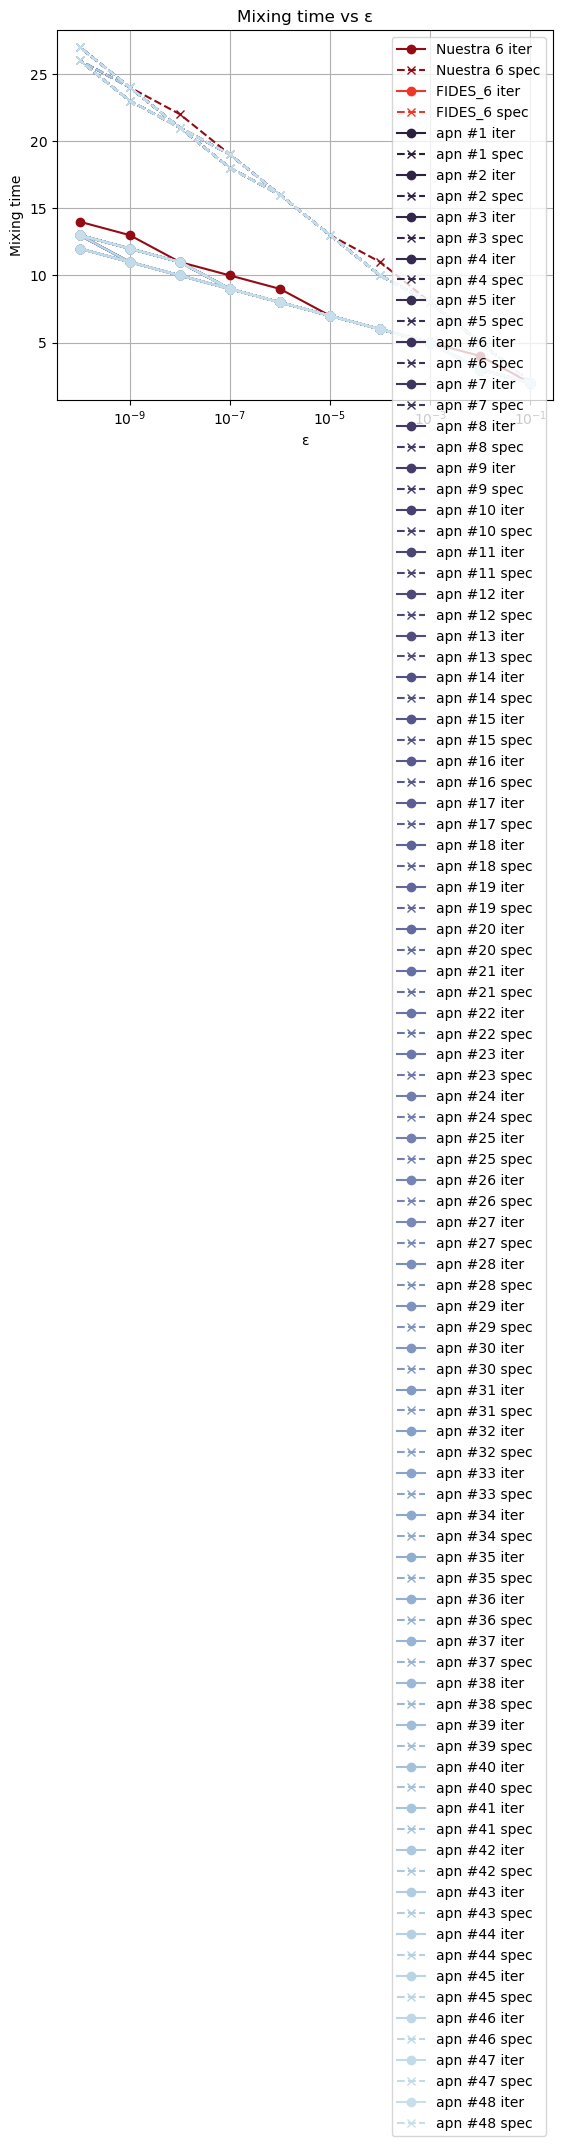

In [13]:
ans = compare_mixing_times(specs, detail=True, graphic=True, log_scale=True)    

0 -> 46
1 -> 56
2 -> 16
3 -> 57
4 -> 0
5 -> 61
6 -> 4
7 -> 62
8 -> 19
9 -> 35
10 -> 33
11 -> 9
12 -> 32
13 -> 39
14 -> 53
15 -> 22
16 -> 31
17 -> 20
18 -> 18
19 -> 58
20 -> 51
21 -> 47
22 -> 11
23 -> 24
24 -> 10
25 -> 36
26 -> 43
27 -> 42
28 -> 54
29 -> 48
30 -> 3
31 -> 63
32 -> 41
33 -> 55
34 -> 26
35 -> 12
36 -> 50
37 -> 44
38 -> 23
39 -> 60
40 -> 45
41 -> 52
42 -> 38
43 -> 29
44 -> 37
45 -> 5
46 -> 14
47 -> 34
48 -> 13
49 -> 8
50 -> 1
51 -> 27
52 -> 21
53 -> 2
54 -> 28
55 -> 59
56 -> 17
57 -> 40
58 -> 7
59 -> 15
60 -> 30
61 -> 49
62 -> 6
63 -> 25
0 -> 54
1 -> 0
2 -> 48
3 -> 13
4 -> 15
5 -> 18
6 -> 35
7 -> 53
8 -> 63
9 -> 25
10 -> 45
11 -> 52
12 -> 3
13 -> 20
14 -> 33
15 -> 41
16 -> 8
17 -> 10
18 -> 57
19 -> 37
20 -> 59
21 -> 36
22 -> 34
23 -> 2
24 -> 26
25 -> 50
26 -> 28
27 -> 24
28 -> 60
29 -> 19
30 -> 14
31 -> 42
32 -> 46
33 -> 61
34 -> 5
35 -> 49
36 -> 31
37 -> 11
38 -> 28
39 -> 4
40 -> 12
41 -> 30
42 -> 55
43 -> 22
44 -> 9
45 -> 6
46 -> 32
47 -> 23
48 -> 27
49 -> 39
50 -> 21
51 

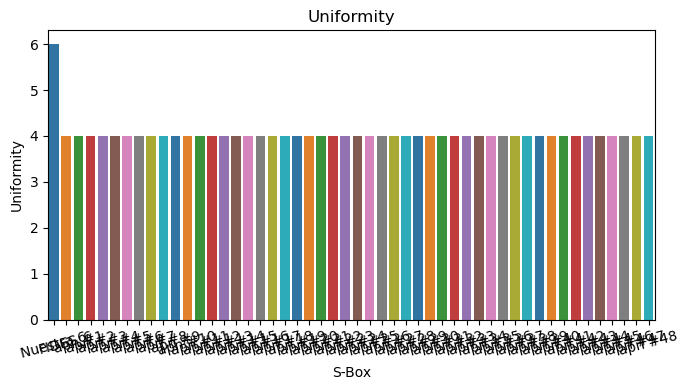

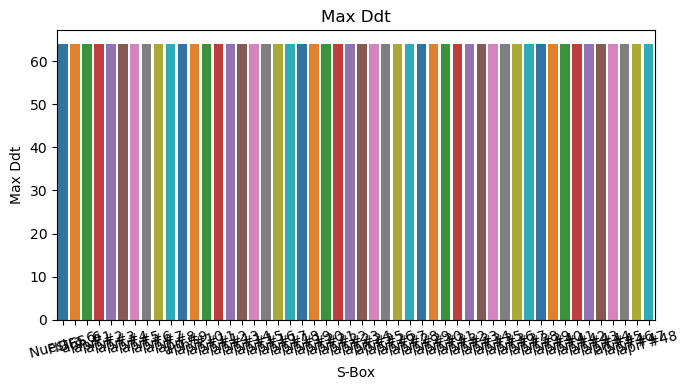

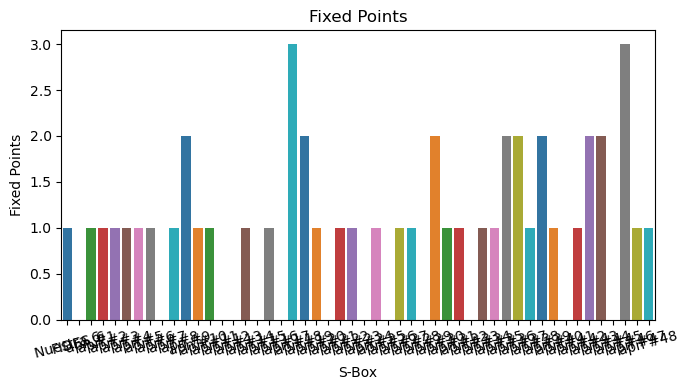

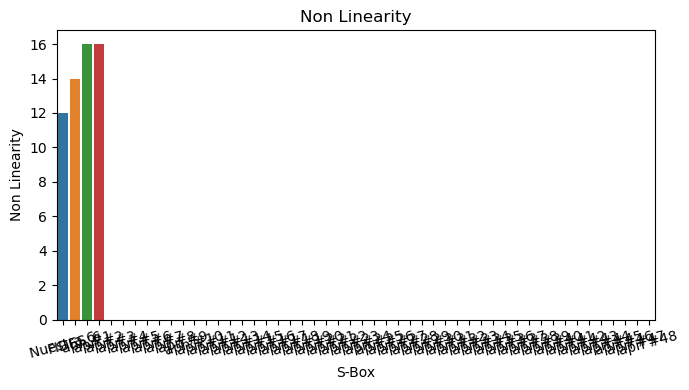

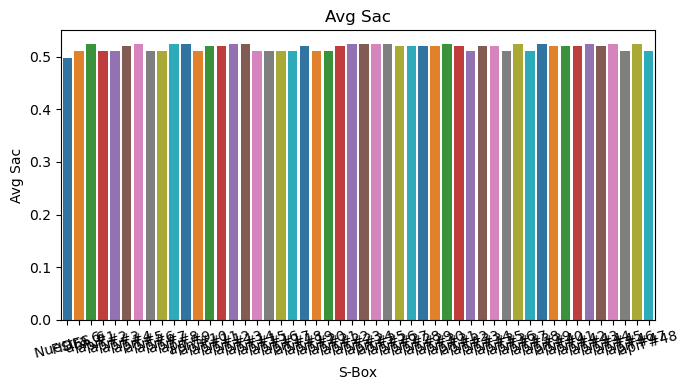

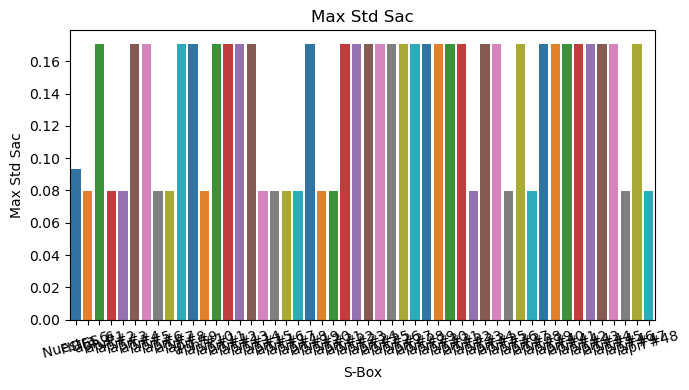

,name,uniformity,max_ddt,fixed_points,non_linearity,avg_sac,max_std_sac
0,Nuestra 6,6,64,1,12.0,0.498264,0.093169
1,FIDES_6,4,64,0,14.0,0.510417,0.079502
2,apn #1,4,64,1,16.0,0.524306,0.170608
3,apn #2,4,64,1,16.0,0.510417,0.079502
4,apn #3,4,64,1,NaN,0.510417,0.079502
5,apn #4,4,64,1,NaN,0.520833,0.170608
6,apn #5,4,64,1,NaN,0.524306,0.170608
7,apn #6,4,64,1,NaN,0.510417,0.079502
8,apn #7,4,64,0,NaN,0.510417,0.079502
9,apn #8,4,64,1,NaN,0.524306,0.170608


In [14]:
from evaluation.sbox_metrics_analysis import run_all_metrics

# Define specs (como ya haces) y tus valores de no-linealidad:
non_linearities = [12, 14, 16, 16]  # valores que tú determines
run_all_metrics(specs, non_linearities)